# 🚀 Pelatihan SSD MobileNet V2 (Skenario 3 & 4) via TensorFlow 2 Object Detection API
**Skripsi:** Analisis Pengaruh Preprocessing CLAHE terhadap Akurasi Deteksi Objek Mikro pada Kemasan Transparan
**Peneliti:** Nadhif Rif'at Rasendriya

Notebook ini secara spesifik dikonfigurasi untuk melatih arsitektur **SSD MobileNet V2 FPNLite 320x320** menggunakan kerangka kerja resmi **TensorFlow 2.x**. Model ini bertindak sebagai *baseline* pembanding yang berkeadilan (*fair comparison*) terhadap model usulan YOLOv5s.

# Skenario 3 | SSD MobileNet V2 (original)

In [ ]:
!pip install -q roboflow pyyaml

import shutil, os

# Paksa bersih total sebelum download ulang — supaya tidak ada sisa split lama
!rm -rf /content/DatasetSkripsi-1
if os.path.exists('dataset_path.txt'):
    os.remove('dataset_path.txt')

from roboflow import Roboflow

print("☁️ Mengunduh dataset dari Roboflow (fresh, tanpa cache lama)...")
rf = Roboflow(api_key="mqzu0AtL172Rw5BZNWr3")
project = rf.workspace("nadhifs-workspace").project("datasetskripsi-g9pqj")
version = project.version(1)
dataset = version.download("yolov5")

with open('dataset_path.txt', 'w') as f:
    f.write(dataset.location)

train_img_dir = os.path.join(dataset.location, "train", "images")
valid_img_dir = os.path.join(dataset.location, "valid", "images")
assert os.path.isdir(train_img_dir), f"❌ Folder tidak ditemukan: {train_img_dir}"
n_train = len([f for f in os.listdir(train_img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
n_valid = len([f for f in os.listdir(valid_img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]) if os.path.isdir(valid_img_dir) else 0
print(f"✅ Dataset OK: {dataset.location}")
print(f"   train: {n_train} gambar | valid: {n_valid} gambar")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.5 MB/s eta 0:00:00
☁️ Mengunduh dataset dari Roboflow (fresh, tanpa cache lama)...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to DatasetSkripsi-1 in yolov5pytorch:: 100%|██████████| 607/607 [00:00<00:00, 4082.52it/s]

✅ Dataset OK: /content/DatasetSkripsi-1
   train: 302 gambar | valid: 0 gambar


In [ ]:
# # Cell 1.5 — Split lokal train -> train/valid (80/20), karena dataset Roboflow
# # belum di-split (semua 302 gambar masuk folder train).
# import os, random, shutil

# random.seed(42)  # fixed seed supaya split reproducible untuk laporan skripsi
# VAL_RATIO = 0.2

# with open('dataset_path.txt') as f:
#     dataset_loc = f.read().strip()

# train_img_dir = os.path.join(dataset_loc, "train", "images")
# train_lbl_dir = os.path.join(dataset_loc, "train", "labels")
# valid_img_dir = os.path.join(dataset_loc, "valid", "images")
# valid_lbl_dir = os.path.join(dataset_loc, "valid", "labels")
# os.makedirs(valid_img_dir, exist_ok=True)
# os.makedirs(valid_lbl_dir, exist_ok=True)

# # Idempoten: kalau valid sudah pernah diisi, jangan split ulang (hindari kebocoran data)
# if len(os.listdir(valid_img_dir)) > 0:
#     print(f"⚠️ Folder valid sudah berisi {len(os.listdir(valid_img_dir))} gambar. "
#           f"Split dilewati supaya tidak terjadi duplikasi/kebocoran data.")
# else:
#     img_files = [f for f in os.listdir(train_img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
#     random.shuffle(img_files)
#     n_val = int(len(img_files) * VAL_RATIO)
#     val_files = img_files[:n_val]

#     for f in val_files:
#         stem = os.path.splitext(f)[0]
#         lbl_f = stem + ".txt"
#         shutil.move(os.path.join(train_img_dir, f), os.path.join(valid_img_dir, f))
#         src_lbl = os.path.join(train_lbl_dir, lbl_f)
#         if os.path.exists(src_lbl):
#             shutil.move(src_lbl, os.path.join(valid_lbl_dir, lbl_f))

#     print(f"✅ Split selesai: {len(img_files) - n_val} gambar train, {n_val} gambar valid.")

# # Verifikasi akhir
# n_train_final = len([f for f in os.listdir(train_img_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))])
# n_valid_final = len([f for f in os.listdir(valid_img_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))])
# print(f"📦 Total sekarang -> train: {n_train_final} | valid: {n_valid_final}")

In [ ]:
%%writefile ssd_utils.py
"""
ssd_utils.py — anchor generation (fine-grained utk objek kecil & rapat),
encoding/decoding bbox, IoU, dan perhitungan AP.
"""
import numpy as np
import tensorflow as tf

IMG_SIZE = 320
VARIANCES = np.array([0.1, 0.1, 0.2, 0.2], dtype=np.float32)

# Ditambah level 40x40 (stride 8) + scale anchor diperkecil drastis (3%-70%)
# supaya cocok untuk objek kecil & padat seperti peer spring dalam kantong.
FEATURE_MAPS = [40, 20, 10, 5, 3, 1]
ASPECT_RATIOS = [
    [1.0, 2.0, 0.5, 3.0, 1.0 / 3.0],
    [1.0, 2.0, 0.5, 3.0, 1.0 / 3.0],
    [1.0, 2.0, 0.5, 3.0, 1.0 / 3.0],
    [1.0, 2.0, 0.5],
    [1.0, 2.0, 0.5],
    [1.0, 2.0, 0.5],
]
NUM_BOXES_PER_CELL = [6, 6, 6, 4, 4, 4]
SCALES = [0.03, 0.144, 0.258, 0.372, 0.486, 0.6, 0.7]


def generate_anchors():
    anchors = []
    for k, g in enumerate(FEATURE_MAPS):
        sk = SCALES[k]
        sk_next = SCALES[k + 1]
        sk_prime = np.sqrt(sk * sk_next)
        ratios = ASPECT_RATIOS[k]
        for i in range(g):
            for j in range(g):
                cx = (j + 0.5) / g
                cy = (i + 0.5) / g
                for r in ratios:
                    w = sk * np.sqrt(r)
                    h = sk / np.sqrt(r)
                    anchors.append((cx, cy, w, h))
                    if r == 1.0:
                        anchors.append((cx, cy, sk_prime, sk_prime))
    return np.array(anchors, dtype=np.float32)


def to_corners(boxes_cxcywh):
    cx, cy, w, h = np.split(boxes_cxcywh, 4, axis=-1)
    xmin, ymin = cx - w / 2, cy - h / 2
    xmax, ymax = cx + w / 2, cy + h / 2
    return np.concatenate([xmin, ymin, xmax, ymax], axis=-1)


def iou_matrix(boxes_a_corners, boxes_b_corners):
    a = boxes_a_corners[:, None, :]
    b = boxes_b_corners[None, :, :]
    inter_xmin = np.maximum(a[..., 0], b[..., 0])
    inter_ymin = np.maximum(a[..., 1], b[..., 1])
    inter_xmax = np.minimum(a[..., 2], b[..., 2])
    inter_ymax = np.minimum(a[..., 3], b[..., 3])
    inter_w = np.clip(inter_xmax - inter_xmin, 0, None)
    inter_h = np.clip(inter_ymax - inter_ymin, 0, None)
    inter = inter_w * inter_h
    area_a = np.clip(a[..., 2] - a[..., 0], 0, None) * np.clip(a[..., 3] - a[..., 1], 0, None)
    area_b = np.clip(b[..., 2] - b[..., 0], 0, None) * np.clip(b[..., 3] - b[..., 1], 0, None)
    union = area_a + area_b - inter
    return inter / np.maximum(union, 1e-8)


def encode_single_image(gt_boxes, gt_classes, anchors, pos_iou_thresh=0.5):
    n_anchors = anchors.shape[0]
    loc_targets = np.zeros((n_anchors, 4), dtype=np.float32)
    cls_targets = np.zeros((n_anchors,), dtype=np.int64)
    if gt_boxes.shape[0] == 0:
        return loc_targets, cls_targets

    anchors_corners = to_corners(anchors)
    gt_corners = to_corners(gt_boxes)
    ious = iou_matrix(anchors_corners, gt_corners)

    best_gt_per_anchor = np.argmax(ious, axis=1)
    best_iou_per_anchor = np.max(ious, axis=1)
    best_anchor_per_gt = np.argmax(ious, axis=0)

    pos_mask = best_iou_per_anchor >= pos_iou_thresh
    pos_mask[best_anchor_per_gt] = True
    best_gt_per_anchor[best_anchor_per_gt] = np.arange(gt_boxes.shape[0])

    matched_gt = gt_boxes[best_gt_per_anchor]
    matched_cls = gt_classes[best_gt_per_anchor]

    acx, acy, aw, ah = anchors[:, 0], anchors[:, 1], anchors[:, 2], anchors[:, 3]
    gcx, gcy, gw, gh = matched_gt[:, 0], matched_gt[:, 1], matched_gt[:, 2], matched_gt[:, 3]

    loc_targets[:, 0] = (gcx - acx) / aw / VARIANCES[0]
    loc_targets[:, 1] = (gcy - acy) / ah / VARIANCES[1]
    loc_targets[:, 2] = np.log(np.maximum(gw, 1e-8) / aw) / VARIANCES[2]
    loc_targets[:, 3] = np.log(np.maximum(gh, 1e-8) / ah) / VARIANCES[3]

    cls_targets[pos_mask] = matched_cls[pos_mask] + 1
    return loc_targets, cls_targets


def decode_boxes(loc_preds, anchors):
    acx, acy, aw, ah = anchors[..., 0], anchors[..., 1], anchors[..., 2], anchors[..., 3]
    tx = loc_preds[..., 0] * VARIANCES[0]
    ty = loc_preds[..., 1] * VARIANCES[1]
    tw = loc_preds[..., 2] * VARIANCES[2]
    th = loc_preds[..., 3] * VARIANCES[3]
    cx = tx * aw + acx
    cy = ty * ah + acy
    w = np.exp(np.clip(tw, -10, 10)) * aw
    h = np.exp(np.clip(th, -10, 10)) * ah
    return np.stack([cx, cy, w, h], axis=-1)


def compute_ap(recall, precision):
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([0.0], precision, [0.0]))
    for i in range(mpre.size - 1, 0, -1):
        mpre[i - 1] = np.maximum(mpre[i - 1], mpre[i])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1])


def evaluate_class_ap(preds, gts, iou_thresh=0.5):
    preds = sorted(preds, key=lambda x: -x[1])
    gt_by_img = {}
    for img_id, box in gts:
        gt_by_img.setdefault(img_id, []).append(box)
    matched = {k: np.zeros(len(v), dtype=bool) for k, v in gt_by_img.items()}

    n_gt = len(gts)
    tp = np.zeros(len(preds))
    fp = np.zeros(len(preds))
    for i, (img_id, score, box) in enumerate(preds):
        gt_boxes = gt_by_img.get(img_id, [])
        if len(gt_boxes) == 0:
            fp[i] = 1
            continue
        ious = iou_matrix(np.array([box]), np.array(gt_boxes))[0]
        j = np.argmax(ious)
        if ious[j] >= iou_thresh and not matched[img_id][j]:
            tp[i] = 1
            matched[img_id][j] = True
        else:
            fp[i] = 1

    tp_cum, fp_cum = np.cumsum(tp), np.cumsum(fp)
    recall = tp_cum / max(n_gt, 1)
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-8)
    ap = compute_ap(recall, precision)
    final_recall = recall[-1] if len(recall) else 0.0
    final_precision = precision[-1] if len(precision) else 0.0
    return ap, final_recall, final_precision

Writing ssd_utils.py


In [ ]:
%%writefile ssd_model.py
"""
ssd_model.py — SSD + backbone MobileNetV2, dengan feature map tambahan 40x40
(stride 8) khusus untuk mendeteksi objek kecil & padat.
"""
import tensorflow as tf
from ssd_utils import FEATURE_MAPS, NUM_BOXES_PER_CELL, IMG_SIZE


def build_ssd_mobilenetv2(num_classes, img_size=IMG_SIZE, pretrained=True):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(img_size, img_size, 3),
        include_top=False,
        weights="imagenet" if pretrained else None,
    )
    fmap0 = base.get_layer("block_6_expand_relu").output   # 40x40 (stride 8) — anchor kecil
    fmap1 = base.get_layer("block_13_expand_relu").output  # 20x20
    fmap2 = base.output  # out_relu, 10x10

    x = tf.keras.layers.Conv2D(256, 1, activation="relu", padding="same")(fmap2)
    x = tf.keras.layers.Conv2D(512, 3, strides=2, activation="relu", padding="same")(x)
    fmap3 = x  # 5x5

    x = tf.keras.layers.Conv2D(128, 1, activation="relu", padding="same")(fmap3)
    x = tf.keras.layers.Conv2D(256, 3, strides=2, activation="relu", padding="same")(x)
    fmap4 = x  # 3x3

    x = tf.keras.layers.Conv2D(128, 1, activation="relu", padding="same")(fmap4)
    x = tf.keras.layers.Conv2D(256, 3, strides=1, padding="valid", activation="relu")(x)
    fmap5 = x  # 1x1

    feature_maps = [fmap0, fmap1, fmap2, fmap3, fmap4, fmap5]
    num_classes_with_bg = num_classes + 1

    loc_outputs, cls_outputs = [], []
    for i, (fmap, n_boxes) in enumerate(zip(feature_maps, NUM_BOXES_PER_CELL)):
        loc = tf.keras.layers.Conv2D(n_boxes * 4, 3, padding="same", name=f"loc_head_{i}")(fmap)
        cls = tf.keras.layers.Conv2D(
            n_boxes * num_classes_with_bg, 3, padding="same", name=f"cls_head_{i}"
        )(fmap)
        loc = tf.keras.layers.Reshape((-1, 4))(loc)
        cls = tf.keras.layers.Reshape((-1, num_classes_with_bg))(cls)
        loc_outputs.append(loc)
        cls_outputs.append(cls)

    loc_out = tf.keras.layers.Concatenate(axis=1, name="loc_preds")(loc_outputs)
    cls_out = tf.keras.layers.Concatenate(axis=1, name="cls_preds")(cls_outputs)

    return tf.keras.Model(inputs=base.input, outputs=[loc_out, cls_out], name="ssd_mobilenetv2")


def multibox_loss(loc_targets, cls_targets, loc_preds, cls_preds, neg_pos_ratio=3.0):
    pos_mask = tf.cast(cls_targets > 0, tf.float32)
    num_pos = tf.reduce_sum(pos_mask, axis=1)

    diff = loc_targets - loc_preds
    abs_diff = tf.abs(diff)
    quadratic = tf.minimum(abs_diff, 1.0)
    linear = abs_diff - quadratic
    loc_loss_per_anchor = tf.reduce_sum(0.5 * quadratic ** 2 + linear, axis=-1)
    loc_loss = tf.reduce_sum(loc_loss_per_anchor * pos_mask, axis=1)

    ce = tf.nn.sparse_softmax_cross_entropy_with_logits(labels=cls_targets, logits=cls_preds)

    neg_mask_candidates = 1.0 - pos_mask
    num_neg = tf.minimum(neg_pos_ratio * num_pos, tf.reduce_sum(neg_mask_candidates, axis=1))
    num_neg = tf.maximum(num_neg, 1.0)

    neg_ce = ce * neg_mask_candidates
    sorted_idx = tf.argsort(neg_ce, axis=1, direction="DESCENDING")
    ranks = tf.argsort(sorted_idx, axis=1)
    neg_keep_mask = tf.cast(tf.cast(ranks, tf.float32) < tf.expand_dims(num_neg, 1), tf.float32)
    neg_keep_mask *= neg_mask_candidates

    cls_loss = tf.reduce_sum(ce * pos_mask, axis=1) + tf.reduce_sum(ce * neg_keep_mask, axis=1)

    denom = tf.maximum(num_pos, 1.0)
    total_loss = tf.reduce_mean((loc_loss + cls_loss) / denom)
    return total_loss, tf.reduce_mean(loc_loss / denom), tf.reduce_mean(cls_loss / denom)

Writing ssd_model.py


In [ ]:
%%writefile data_pipeline.py
"""
data_pipeline.py — Membaca dataset format YOLOv5 (hasil download Roboflow),
mem-parsing bounding box asli dari file .txt, lalu meng-encode-nya ke target anchor SSD.
"""
import os
import random
import cv2
import numpy as np
import tensorflow as tf
from ssd_utils import generate_anchors, encode_single_image, IMG_SIZE

IMG_EXTS = (".jpg", ".jpeg", ".png")


def list_image_label_pairs(img_dir, lbl_dir):
    pairs = []
    if not os.path.isdir(img_dir):
        return pairs
    for f in sorted(os.listdir(img_dir)):
        if not f.lower().endswith(IMG_EXTS):
            continue
        stem = os.path.splitext(f)[0]
        lbl_path = os.path.join(lbl_dir, stem + ".txt")
        pairs.append((os.path.join(img_dir, f), lbl_path))
    return pairs


def parse_yolo_label(lbl_path):
    if not os.path.exists(lbl_path) or os.path.getsize(lbl_path) == 0:
        return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.int64)
    boxes, classes = [], []
    with open(lbl_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id = int(float(parts[0]))
            cx, cy, w, h = map(float, parts[1:5])
            boxes.append([cx, cy, w, h])
            classes.append(cls_id)
    if not boxes:
        return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.int64)
    return np.array(boxes, dtype=np.float32), np.array(classes, dtype=np.int64)


def load_image(path, img_size=IMG_SIZE):
    img = cv2.imread(path)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (img_size, img_size))
    return (img / 255.0).astype(np.float32)


def make_dataset(img_dir, lbl_dir, batch_size=16, img_size=IMG_SIZE,
                  augment=False, shuffle=True, anchors=None):
    if anchors is None:
        anchors = generate_anchors()
    pairs = list_image_label_pairs(img_dir, lbl_dir)
    if len(pairs) == 0:
        raise FileNotFoundError(f"Tidak ada gambar ditemukan di: {img_dir}")
    n_anchors = anchors.shape[0]

    def gen():
        local_pairs = pairs.copy()
        if shuffle:
            random.shuffle(local_pairs)
        for img_path, lbl_path in local_pairs:
            img = load_image(img_path, img_size)
            if img is None:
                continue
            gt_boxes, gt_classes = parse_yolo_label(lbl_path)

            if augment and random.random() < 0.5:
                img = img[:, ::-1, :].copy()
                if gt_boxes.shape[0] > 0:
                    gt_boxes = gt_boxes.copy()
                    gt_boxes[:, 0] = 1.0 - gt_boxes[:, 0]

            loc_t, cls_t = encode_single_image(gt_boxes, gt_classes, anchors)
            yield img, loc_t, cls_t

    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec(shape=(img_size, img_size, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(n_anchors, 4), dtype=tf.float32),
            tf.TensorSpec(shape=(n_anchors,), dtype=tf.int64),
        ),
    )
    ds = ds.batch(batch_size, drop_remainder=False).prefetch(tf.data.AUTOTUNE)
    return ds, len(pairs)

Writing data_pipeline.py


In [ ]:
%%writefile train_ssd.py
import os, json, time
import yaml
import tensorflow as tf
from ssd_utils import generate_anchors, IMG_SIZE
from ssd_model import build_ssd_mobilenetv2, multibox_loss
from data_pipeline import make_dataset

print(f"✅ TensorFlow versi: {tf.__version__}")
gpu = len(tf.config.list_physical_devices('GPU')) > 0
print(f"🚀 GPU: {'Aktif' if gpu else 'Tidak aktif (CPU)'}")

EPOCHS = 150
BATCH_SIZE = 16
INITIAL_LR = 1e-3
CKPT_DIR = "/content/models/S3_Native_SSD"
os.makedirs(CKPT_DIR, exist_ok=True)

with open('dataset_path.txt', 'r') as f:
    dataset_loc = f.read().strip()

with open(os.path.join(dataset_loc, 'data.yaml')) as f:
    data_cfg = yaml.safe_load(f)
class_names = data_cfg['names']
num_classes = data_cfg['nc']
print(f"📋 Jumlah kelas: {num_classes} -> {class_names}")
with open(os.path.join(CKPT_DIR, 'classes.json'), 'w') as f:
    json.dump({"names": class_names, "nc": num_classes}, f)

train_img_dir = os.path.join(dataset_loc, "train", "images")
train_lbl_dir = os.path.join(dataset_loc, "train", "labels")
valid_img_dir = os.path.join(dataset_loc, "valid", "images")
valid_lbl_dir = os.path.join(dataset_loc, "valid", "labels")

anchors = generate_anchors()
print(f"⚙️ Total anchor box: {anchors.shape[0]}")

train_ds, n_train = make_dataset(train_img_dir, train_lbl_dir, BATCH_SIZE,
                                  augment=True, shuffle=True, anchors=anchors)
if os.path.isdir(valid_img_dir) and len(os.listdir(valid_img_dir)) > 0:
    valid_ds, n_valid = make_dataset(valid_img_dir, valid_lbl_dir, BATCH_SIZE,
                                      augment=False, shuffle=False, anchors=anchors)
else:
    print("⚠️ Folder validasi kosong, memakai sebagian data train untuk validasi.")
    valid_ds, n_valid = make_dataset(train_img_dir, train_lbl_dir, BATCH_SIZE,
                                      augment=False, shuffle=False, anchors=anchors)
print(f"📦 Train: {n_train} gambar | Valid: {n_valid} gambar")

steps_per_epoch = max(1, n_train // BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(INITIAL_LR, total_steps, alpha=0.01)
optimizer = tf.keras.optimizers.Adam(lr_schedule)

model = build_ssd_mobilenetv2(num_classes, pretrained=True)
print(f"⚙️ Total parameter model: {model.count_params():,}")

@tf.function
def train_step(images, loc_t, cls_t):
    with tf.GradientTape() as tape:
        loc_preds, cls_preds = model(images, training=True)
        loss, loc_l, cls_l = multibox_loss(loc_t, cls_t, loc_preds, cls_preds)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss, loc_l, cls_l

@tf.function
def val_step(images, loc_t, cls_t):
    loc_preds, cls_preds = model(images, training=False)
    return multibox_loss(loc_t, cls_t, loc_preds, cls_preds)

print("🔥 Memulai training SSD MobileNetV2 native...")
best_val_loss = float("inf")
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_losses = []
    for images, loc_t, cls_t in train_ds:
        loss, loc_l, cls_l = train_step(images, loc_t, cls_t)
        train_losses.append(float(loss))
    train_loss = sum(train_losses) / len(train_losses)

    val_losses = []
    for images, loc_t, cls_t in valid_ds:
        loss, loc_l, cls_l = val_step(images, loc_t, cls_t)
        val_losses.append(float(loss))
    val_loss = sum(val_losses) / len(val_losses)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    dt = time.time() - t0
    print(f"Epoch {epoch:3d}/{EPOCHS} | train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | {dt:.1f}s")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        model.save_weights(os.path.join(CKPT_DIR, "best.weights.h5"))
    if epoch % 10 == 0 or epoch == EPOCHS:
        model.save_weights(os.path.join(CKPT_DIR, "last.weights.h5"))

with open(os.path.join(CKPT_DIR, "history.json"), "w") as f:
    json.dump(history, f)

print(f"✅ BINGO! Training selesai. Bobot terbaik disimpan di: {CKPT_DIR}/best.weights.h5")

Overwriting train_ssd.py


In [ ]:
import os
required_files = ['ssd_utils.py', 'ssd_model.py', 'data_pipeline.py', 'train_ssd.py']
missing = [f for f in required_files if not os.path.exists(f)]
if missing:
    print(f"❌ File belum ada, jalankan ulang cell %%writefile untuk: {missing}")
else:
    print("✅ Semua file modul sudah lengkap, aman untuk training.")

✅ Semua file modul sudah lengkap, aman untuk training.


In [ ]:
import ast
for fname in ['ssd_utils.py', 'ssd_model.py', 'data_pipeline.py', 'train_ssd.py']:
    try:
        with open(fname) as f:
            ast.parse(f.read())
        print(f"✅ {fname} — syntax valid")
    except SyntaxError as e:
        print(f"❌ {fname} — SYNTAX ERROR: {e}")

✅ ssd_utils.py — syntax valid
✅ ssd_model.py — syntax valid
✅ data_pipeline.py — syntax valid
✅ train_ssd.py — syntax valid


In [ ]:
!python train_ssd.py

✅ TensorFlow versi: 2.20.0
🚀 GPU: Aktif
📋 Jumlah kelas: 1 -> ['spring']
⚙️ Total anchor box: 12740
2026-09-12 13:43:37.542375: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1789220617.544353   12954 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12361 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
⚠️ Folder validasi kosong, memakai sebagian data train untuk validasi.
📦 Train: 302 gambar | Valid: 302 gambar
/content/ssd_model.py:10: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(
⚙️ Total parameter model: 5,339,892
🔥 Memulai training SSD MobileNetV2 native...
Epoch   1/150 | train_loss=7.1362 |

In [ ]:
import importlib
import ssd_utils, ssd_model, data_pipeline
importlib.reload(ssd_utils)
importlib.reload(ssd_model)
importlib.reload(data_pipeline)

from ssd_utils import generate_anchors, decode_boxes, to_corners, evaluate_class_ap, iou_matrix
from ssd_model import build_ssd_mobilenetv2
from data_pipeline import list_image_label_pairs, parse_yolo_label, load_image, IMG_SIZE


=== HASIL EVALUASI SSD MobileNetV2 (native, TF/Keras) ===

Class           Images   Instances         P         R     mAP50    mAP50-95
all                302        7256     0.948     0.244     0.244       0.203
spring             302        7256     0.948     0.244     0.244       0.203

✅ Metrik tersimpan di: /content/models/S3_Native_SSD/metrics.json


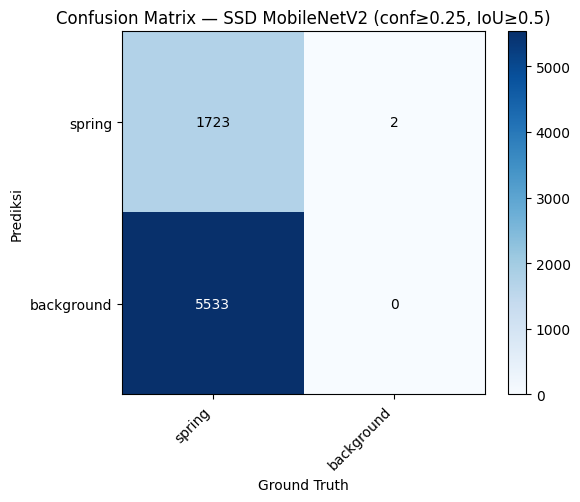

In [ ]:
import os, json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from ssd_utils import generate_anchors, decode_boxes, to_corners, evaluate_class_ap, iou_matrix
from ssd_model import build_ssd_mobilenetv2
from data_pipeline import list_image_label_pairs, parse_yolo_label, load_image, IMG_SIZE

CKPT_DIR = "/content/models/S3_Native_SSD"
with open('dataset_path.txt') as f:
    dataset_loc = f.read().strip()
with open(os.path.join(CKPT_DIR, 'classes.json')) as f:
    meta = json.load(f)
class_names, num_classes = meta["names"], meta["nc"]

valid_img_dir = os.path.join(dataset_loc, "valid", "images")
valid_lbl_dir = os.path.join(dataset_loc, "valid", "labels")
if not (os.path.isdir(valid_img_dir) and len(os.listdir(valid_img_dir)) > 0):
    valid_img_dir = os.path.join(dataset_loc, "train", "images")
    valid_lbl_dir = os.path.join(dataset_loc, "train", "labels")

anchors = generate_anchors()
model = build_ssd_mobilenetv2(num_classes, pretrained=False)
model.load_weights(os.path.join(CKPT_DIR, "best.weights.h5"))

pairs = list_image_label_pairs(valid_img_dir, valid_lbl_dir)
CONF_THRESH_MAP = 0.01
NMS_IOU = 0.45

all_preds = {c: [] for c in range(num_classes)}
all_gts = {c: [] for c in range(num_classes)}
n_instances_per_class = {c: 0 for c in range(num_classes)}

for img_id, (img_path, lbl_path) in enumerate(pairs):
    img = load_image(img_path, IMG_SIZE)
    if img is None:
        continue
    gt_boxes, gt_classes = parse_yolo_label(lbl_path)
    gt_corners = to_corners(gt_boxes) if gt_boxes.shape[0] > 0 else np.zeros((0, 4))
    for box, cls in zip(gt_corners, gt_classes):
        all_gts[int(cls)].append((img_id, box))
        n_instances_per_class[int(cls)] += 1

    loc_preds, cls_preds = model(np.expand_dims(img, 0), training=False)
    probs = tf.nn.softmax(cls_preds, axis=-1).numpy()[0]
    decoded = decode_boxes(loc_preds.numpy()[0], anchors)
    decoded_corners = to_corners(decoded)

    for c in range(1, num_classes + 1):
        scores = probs[:, c]
        keep = tf.image.non_max_suppression(
            decoded_corners, scores, max_output_size=50,
            iou_threshold=NMS_IOU, score_threshold=CONF_THRESH_MAP).numpy()
        for k in keep:
            all_preds[c - 1].append((img_id, float(scores[k]), decoded_corners[k]))

# --- mAP50 & mAP50-95 (COCO-style, rata-rata IoU 0.50:0.05:0.95) ---
iou_thresholds = np.arange(0.5, 1.0, 0.05)
per_class_ap50, per_class_ap5095, per_class_p, per_class_r = {}, {}, {}, {}
for c in range(num_classes):
    ap50, r50, p50 = evaluate_class_ap(all_preds[c], all_gts[c], iou_thresh=0.5)
    aps_all_iou = [evaluate_class_ap(all_preds[c], all_gts[c], iou_thresh=t)[0] for t in iou_thresholds]
    per_class_ap50[c] = ap50
    per_class_ap5095[c] = float(np.mean(aps_all_iou))
    per_class_p[c] = p50
    per_class_r[c] = r50

mAP50 = float(np.mean(list(per_class_ap50.values())))
mAP5095 = float(np.mean(list(per_class_ap5095.values())))
mean_p = float(np.mean(list(per_class_p.values())))
mean_r = float(np.mean(list(per_class_r.values())))
n_images = len(pairs)
n_instances_total = sum(n_instances_per_class.values())

print("\n=== HASIL EVALUASI SSD MobileNetV2 (native, TF/Keras) ===\n")
header = f"{'Class':<12}{'Images':>10}{'Instances':>12}{'P':>10}{'R':>10}{'mAP50':>10}{'mAP50-95':>12}"
print(header)
print(f"{'all':<12}{n_images:>10}{n_instances_total:>12}{mean_p:>10.3f}{mean_r:>10.3f}{mAP50:>10.3f}{mAP5095:>12.3f}")
for c in range(num_classes):
    print(f"{class_names[c]:<12}{n_images:>10}{n_instances_per_class[c]:>12}"
          f"{per_class_p[c]:>10.3f}{per_class_r[c]:>10.3f}{per_class_ap50[c]:>10.3f}{per_class_ap5095[c]:>12.3f}")

metrics = {
    "images": n_images, "instances": n_instances_total,
    "precision": mean_p, "recall": mean_r, "mAP50": mAP50, "mAP50_95": mAP5095,
    "per_class": {class_names[c]: {"P": per_class_p[c], "R": per_class_r[c],
                  "mAP50": per_class_ap50[c], "mAP50_95": per_class_ap5095[c]} for c in range(num_classes)}
}
with open(os.path.join(CKPT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
print(f"\n✅ Metrik tersimpan di: {CKPT_DIR}/metrics.json")

# --- Confusion matrix (threshold conf=0.25, IoU=0.5, mirip default YOLOv5) ---
CONF_THRESH_CM = 0.25
confusion = np.zeros((num_classes + 1, num_classes + 1), dtype=int)
for img_id, (img_path, lbl_path) in enumerate(pairs):
    gt_boxes, gt_classes = parse_yolo_label(lbl_path)
    gt_corners = to_corners(gt_boxes) if gt_boxes.shape[0] > 0 else np.zeros((0, 4))
    dets = []
    for c in range(num_classes):
        for pid, score, box in all_preds[c]:
            if pid == img_id and score >= CONF_THRESH_CM:
                dets.append((box, score, c))
    matched_gt = np.zeros(len(gt_corners), dtype=bool)
    for db, ds_, dc in sorted(dets, key=lambda x: -x[1]):
        if len(gt_corners) > 0:
            ious = iou_matrix(np.array([db]), gt_corners)[0]
            j = np.argmax(ious)
            if ious[j] >= 0.5 and not matched_gt[j]:
                confusion[dc, int(gt_classes[j])] += 1
                matched_gt[j] = True
                continue
        confusion[dc, num_classes] += 1
    for j, matched in enumerate(matched_gt):
        if not matched:
            confusion[num_classes, int(gt_classes[j])] += 1

labels = class_names + ["background"]
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel("Ground Truth"); ax.set_ylabel("Prediksi")
ax.set_title(f"Confusion Matrix — SSD MobileNetV2 (conf≥{CONF_THRESH_CM}, IoU≥0.5)")
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, confusion[i, j], ha="center", va="center",
                 color="white" if confusion[i, j] > confusion.max()/2 else "black")
plt.colorbar(im); plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

In [ ]:
!pip install -q tf2onnx onnx

import os, tensorflow as tf

CKPT_DIR = "/content/models/S3_Native_SSD"

# 1. TFLite (sudah ada dari sebelumnya, tetap disimpan)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
tflite_path = os.path.join(CKPT_DIR, "best_ssd.tflite")
with open(tflite_path, "wb") as f:
    f.write(tflite_model)
print(f"✅ TFLite tersimpan di: {tflite_path}")

# 2. SavedModel (perantara wajib untuk konversi ke ONNX)
saved_model_dir = os.path.join(CKPT_DIR, "saved_model")
tf.saved_model.save(model, saved_model_dir)

# 3. ONNX — biar formatnya konsisten dengan best.onnx YOLOv5 kamu
onnx_path = os.path.join(CKPT_DIR, "best_ssd.onnx")
!python -m tf2onnx.convert --saved-model {saved_model_dir} --output {onnx_path} --opset 13

print(f"✅ ONNX tersimpan di: {onnx_path}")
print(f"✅ Bobot Keras (.h5) tetap ada di: {CKPT_DIR}/best.weights.h5")

Saved artifact at '/tmp/tmp_k1b1scl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 320, 320, 3), dtype=tf.float32, name='keras_tensor_186')
Output Type:
  List[TensorSpec(shape=(None, 12740, 4), dtype=tf.float32, name=None), TensorSpec(shape=(None, 12740, 2), dtype=tf.float32, name=None)]
Captures:
  135048907370384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320691664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320691856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320692048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320689168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320690896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320692432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320691472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135046320692240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13

In [ ]:
!pip install -q gdown
import os
os.makedirs('/content/test_images_static', exist_ok=True)

# Nama file -> Google Drive file ID (diambil dari link yang kamu kirim)
files = {
    "21sementara-normal.jpg": "1YQ9O89YY9uQmrktHp1o7k9X9RkqWRb9f",
    "21sementara-glarelampuhp1.jpg": "1dZrxmrnNiKUJJ0NFIlIbM-vaT57xTphr",
    "21sementara-glarelampuhp2.jpg": "12RavfsKZTuQYMQC9b3pu0loVHlaWWFem",
    "21sementara-glarelampuhp3.jpg": "1j7Zb6JsK-ZxSsEdnlyBLhpVsdQeE1Jbp",
    "21sementara-glarelampuhp4.jpg": "1sT6Dkfg07VhdAC_6mqTUnQUnlOpNxki5",
    "21sementara-glarelampuhp5.jpg": "1I4uroedESzw6TdcIbUsfN9Hsx9ujQC90",
    "21sementara-glarelampuhp6.jpg": "1wKccR4orhfuYbX4CbkRnmnBOsI2gj3zX",
    "21sementara-glarelampuhp7.jpg": "14QpFzVqb7NdXcMbX6UtA5dPWSbq9RyZe",
    "21sementara-glaresenter.jpg": "1oQb8MZi-qGTy2bHyIN75hUiBOG7i_-N-",
    "21sementara-glaresenter2.jpg": "1aZqbk5sUHpY3DU5DRt7nwM934baGCI3R",
    "21sementara-glaresenter3.jpg": "1sUVvJdMFu0z8y0RTIHPokWByPkoys7cr",
    "21sementara-glaresenter4.jpg": "1vc4sj9vJfTwvRXirc8LCkDeH53mmpOwY",
    "21sementara-glaresenter5.jpg": "104uX2tonx_MBaqiXmT5K4m8Pw6cvmoez",
    "21sementara-glaresenter6.jpg": "1tD48heiNxh5F-o-k7KVgQ1VrkZXHSDU9",
}

for fname, fid in files.items():
    out_path = f"/content/test_images_static/{fname}"
    !gdown --id {fid} -O "{out_path}" -q
    status = "✅" if os.path.exists(out_path) else "❌ GAGAL"
    print(f"{status} {fname}")

print(f"\nTotal file terunduh: {len([f for f in files if os.path.exists(f'/content/test_images_static/{f}')])}/14")

21sementara-glarelampuhp1.jpg            -> 5 objek terdeteksi
21sementara-glarelampuhp2.jpg            -> 4 objek terdeteksi
21sementara-glarelampuhp3.jpg            -> 7 objek terdeteksi
21sementara-glarelampuhp4.jpg            -> 5 objek terdeteksi
21sementara-glarelampuhp5.jpg            -> 9 objek terdeteksi
21sementara-glarelampuhp6.jpg            -> 5 objek terdeteksi
21sementara-glarelampuhp7.jpg            -> 3 objek terdeteksi
21sementara-glaresenter.jpg              -> 6 objek terdeteksi
21sementara-glaresenter2.jpg             -> 4 objek terdeteksi
21sementara-glaresenter3.jpg             -> 8 objek terdeteksi
21sementara-glaresenter4.jpg             -> 7 objek terdeteksi
21sementara-glaresenter5.jpg             -> 5 objek terdeteksi
21sementara-glaresenter6.jpg             -> 4 objek terdeteksi
21sementara-normal.jpg                   -> 6 objek terdeteksi


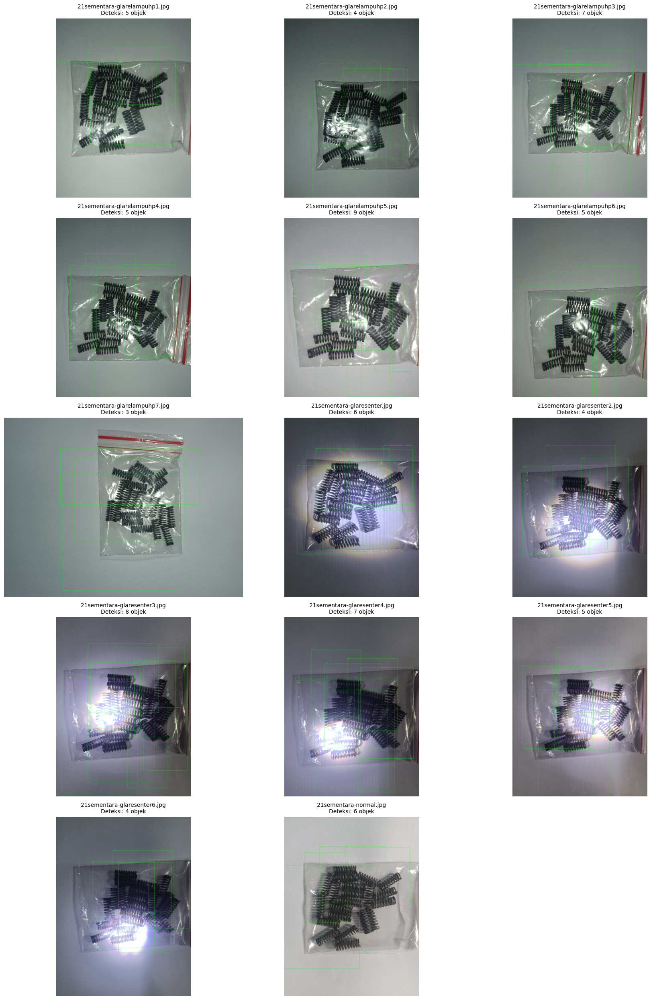


✅ Hasil tersimpan di: /content/models/S3_Native_SSD/hasil_uji_14_citra.png dan .json


In [ ]:
import os, json
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from ssd_utils import generate_anchors, decode_boxes, to_corners
from ssd_model import build_ssd_mobilenetv2

CKPT_DIR = "/content/models/S3_Native_SSD"
CONF_THRESH = 0.50   # disamakan dengan --conf 0.50 di detect.py YOLOv5 kamu
NMS_IOU = 0.45
IMG_SIZE = 320

with open(os.path.join(CKPT_DIR, 'classes.json')) as f:
    meta = json.load(f)
class_names, num_classes = meta["names"], meta["nc"]

anchors = generate_anchors()
model = build_ssd_mobilenetv2(num_classes, pretrained=False)
model.load_weights(os.path.join(CKPT_DIR, "best.weights.h5"))

test_dir = "/content/test_images_static"
out_dir = "/content/detect_SSD_static"
os.makedirs(out_dir, exist_ok=True)

def detect_and_draw(img_path):
    img_bgr = cv2.imread(img_path)
    h0, w0 = img_bgr.shape[:2]
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE)) / 255.0

    loc_preds, cls_preds = model(np.expand_dims(img_resized.astype(np.float32), 0), training=False)
    probs = tf.nn.softmax(cls_preds, axis=-1).numpy()[0]
    decoded = decode_boxes(loc_preds.numpy()[0], anchors)
    decoded_corners = to_corners(decoded)

    final_boxes, final_scores, final_classes = [], [], []
    for c in range(1, num_classes + 1):
        scores = probs[:, c]
        keep = tf.image.non_max_suppression(
            decoded_corners, scores, max_output_size=100,
            iou_threshold=NMS_IOU, score_threshold=CONF_THRESH).numpy()
        for k in keep:
            final_boxes.append(decoded_corners[k])
            final_scores.append(scores[k])
            final_classes.append(c - 1)

    img_out = img_bgr.copy()
    for box, score, cls in zip(final_boxes, final_scores, final_classes):
        xmin, ymin, xmax, ymax = box
        x1, y1, x2, y2 = int(xmin * w0), int(ymin * h0), int(xmax * w0), int(ymax * h0)
        cv2.rectangle(img_out, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img_out, f"{class_names[cls]} {score:.2f}", (x1, max(y1 - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    return img_out, len(final_boxes)

results = {}
for fname in sorted(os.listdir(test_dir)):
    if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue
    img_out, n_detected = detect_and_draw(os.path.join(test_dir, fname))
    cv2.imwrite(os.path.join(out_dir, fname), img_out)
    results[fname] = n_detected
    print(f"{fname:40s} -> {n_detected} objek terdeteksi")

# Visualisasi grid
n = len(results)
cols = 3
rows = (n + cols - 1) // cols
plt.figure(figsize=(6 * cols, 5 * rows))
for i, (fname, n_detected) in enumerate(results.items()):
    img = cv2.cvtColor(cv2.imread(os.path.join(out_dir, fname)), cv2.COLOR_BGR2RGB)
    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.title(f"{fname}\nDeteksi: {n_detected} objek", fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "hasil_uji_14_citra.png"), dpi=150)
plt.show()

with open(os.path.join(CKPT_DIR, "hasil_uji_14_citra.json"), "w") as f:
    json.dump(results, f, indent=2)
print(f"\n✅ Hasil tersimpan di: {CKPT_DIR}/hasil_uji_14_citra.png dan .json")

#Skenario 4 | SSD MobileNet V2 + CLAHE

In [ ]:
   import os, json
   os.makedirs('/content/models/S3_Native_SSD_Original', exist_ok=True)

   # Buat classes.json manual (tidak perlu upload)
   with open('/content/models/S3_Native_SSD_Original/classes.json', 'w') as f:
       json.dump({"names": ["spring"], "nc": 1}, f)
   print("✅ classes.json dibuat")

✅ classes.json dibuat


In [ ]:
   from google.colab import files
   uploaded = files.upload()  # pilih best.weights.h5 dari komputer
   import shutil
   shutil.move('best.weights.h5', '/content/models/S3_Native_SSD_Original/best.weights.h5')
   print("✅ best.weights.h5 Original berhasil dipindah")

Saving best.weights.h5 to best.weights.h5
✅ best.weights.h5 Original berhasil dipindah


In [ ]:
import os, shutil, cv2
from tqdm import tqdm

with open('dataset_path.txt') as f:
    dataset_loc = f.read().strip()

CLIP_LIMIT = 4.0
TILE_GRID = (8, 8)

def apply_clahe_dataset(src_dir, dst_dir, mode):
    if os.path.exists(dst_dir):
        print(f"⚠️ {dst_dir} sudah ada, dilewati (hapus manual dulu kalau mau regenerasi).")
        return
    print(f"📂 Menyalin {src_dir} -> {dst_dir} ...")
    shutil.copytree(src_dir, dst_dir)
    for split in ['train', 'valid', 'test']:
        img_dir = os.path.join(dst_dir, split, 'images')
        if not os.path.isdir(img_dir):
            continue
        files = [f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        for fname in tqdm(files, desc=f"CLAHE-{mode} '{split}'"):
            fpath = os.path.join(img_dir, fname)
            img_bgr = cv2.imread(fpath)
            if img_bgr is None:
                continue
            if mode == 'lab':
                img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
                l, a, b = cv2.split(img_lab)
                clahe = cv2.createCLAHE(clipLimit=CLIP_LIMIT, tileGridSize=TILE_GRID)
                l_clahe = clahe.apply(l)
                result = cv2.merge((l_clahe, l_clahe, l_clahe))  # trik L*L*L*
            elif mode == 'hsv':
                img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
                h, s, v = cv2.split(img_hsv)
                clahe = cv2.createCLAHE(clipLimit=CLIP_LIMIT, tileGridSize=TILE_GRID)
                v_clahe = clahe.apply(v)
                result = cv2.merge((v_clahe, v_clahe, v_clahe))  # trik V*V*V*
            else:
                raise ValueError(mode)
            cv2.imwrite(fpath, result)
    print(f"✅ Dataset CLAHE-{mode} selesai: {dst_dir}\n")

dataset_lab = dataset_loc.rstrip('/') + "-CLAHE-LAB"
dataset_hsv = dataset_loc.rstrip('/') + "-CLAHE-HSV"

apply_clahe_dataset(dataset_loc, dataset_lab, mode='lab')
apply_clahe_dataset(dataset_loc, dataset_hsv, mode='hsv')

with open('dataset_path_lab.txt', 'w') as f:
    f.write(dataset_lab)
with open('dataset_path_hsv.txt', 'w') as f:
    f.write(dataset_hsv)

print(f"✅ dataset_path_lab.txt -> {dataset_lab}")
print(f"✅ dataset_path_hsv.txt -> {dataset_hsv}")

📂 Menyalin /content/DatasetSkripsi-1 -> /content/DatasetSkripsi-1-CLAHE-LAB ...


CLAHE-lab 'train': 100%|██████████| 302/302 [00:02<00:00, 109.43it/s]


✅ Dataset CLAHE-lab selesai: /content/DatasetSkripsi-1-CLAHE-LAB

📂 Menyalin /content/DatasetSkripsi-1 -> /content/DatasetSkripsi-1-CLAHE-HSV ...


CLAHE-hsv 'train': 100%|██████████| 302/302 [00:01<00:00, 162.49it/s]

✅ Dataset CLAHE-hsv selesai: /content/DatasetSkripsi-1-CLAHE-HSV

✅ dataset_path_lab.txt -> /content/DatasetSkripsi-1-CLAHE-LAB
✅ dataset_path_hsv.txt -> /content/DatasetSkripsi-1-CLAHE-HSV


In [ ]:
%%writefile train_ssd.py
import os, json, time, argparse
import yaml
import tensorflow as tf
from ssd_utils import generate_anchors, IMG_SIZE
from ssd_model import build_ssd_mobilenetv2, multibox_loss
from data_pipeline import make_dataset

parser = argparse.ArgumentParser()
parser.add_argument('--dataset_dir', type=str, default=None,
                     help='Path dataset. Default: baca dari dataset_path.txt (dataset original)')
parser.add_argument('--ckpt_dir', type=str, default='/content/models/S3_Native_SSD')
parser.add_argument('--epochs', type=int, default=150)
parser.add_argument('--batch_size', type=int, default=16)
args = parser.parse_args()

print(f"✅ TensorFlow versi: {tf.__version__}")
gpu = len(tf.config.list_physical_devices('GPU')) > 0
print(f"🚀 GPU: {'Aktif' if gpu else 'Tidak aktif (CPU)'}")

EPOCHS = args.epochs
BATCH_SIZE = args.batch_size
INITIAL_LR = 1e-3
CKPT_DIR = args.ckpt_dir
os.makedirs(CKPT_DIR, exist_ok=True)

if args.dataset_dir:
    dataset_loc = args.dataset_dir
else:
    with open('dataset_path.txt', 'r') as f:
        dataset_loc = f.read().strip()

print(f"📂 Dataset : {dataset_loc}")
print(f"💾 Output  : {CKPT_DIR}")

with open(os.path.join(dataset_loc, 'data.yaml')) as f:
    data_cfg = yaml.safe_load(f)
class_names = data_cfg['names']
num_classes = data_cfg['nc']
print(f"📋 Jumlah kelas: {num_classes} -> {class_names}")
with open(os.path.join(CKPT_DIR, 'classes.json'), 'w') as f:
    json.dump({"names": class_names, "nc": num_classes}, f)

train_img_dir = os.path.join(dataset_loc, "train", "images")
train_lbl_dir = os.path.join(dataset_loc, "train", "labels")
valid_img_dir = os.path.join(dataset_loc, "valid", "images")
valid_lbl_dir = os.path.join(dataset_loc, "valid", "labels")

anchors = generate_anchors()
print(f"⚙️ Total anchor box: {anchors.shape[0]}")

train_ds, n_train = make_dataset(train_img_dir, train_lbl_dir, BATCH_SIZE,
                                  augment=True, shuffle=True, anchors=anchors)
if os.path.isdir(valid_img_dir) and len(os.listdir(valid_img_dir)) > 0:
    valid_ds, n_valid = make_dataset(valid_img_dir, valid_lbl_dir, BATCH_SIZE,
                                      augment=False, shuffle=False, anchors=anchors)
else:
    print("⚠️ Folder validasi kosong, memakai sebagian data train untuk validasi.")
    valid_ds, n_valid = make_dataset(train_img_dir, train_lbl_dir, BATCH_SIZE,
                                      augment=False, shuffle=False, anchors=anchors)
print(f"📦 Train: {n_train} gambar | Valid: {n_valid} gambar")

steps_per_epoch = max(1, n_train // BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(INITIAL_LR, total_steps, alpha=0.01)
optimizer = tf.keras.optimizers.Adam(lr_schedule)

model = build_ssd_mobilenetv2(num_classes, pretrained=True)
print(f"⚙️ Total parameter model: {model.count_params():,}")

@tf.function
def train_step(images, loc_t, cls_t):
    with tf.GradientTape() as tape:
        loc_preds, cls_preds = model(images, training=True)
        loss, loc_l, cls_l = multibox_loss(loc_t, cls_t, loc_preds, cls_preds)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss, loc_l, cls_l

@tf.function
def val_step(images, loc_t, cls_t):
    loc_preds, cls_preds = model(images, training=False)
    return multibox_loss(loc_t, cls_t, loc_preds, cls_preds)

print("🔥 Memulai training SSD MobileNetV2 native...")
best_val_loss = float("inf")
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_losses = []
    for images, loc_t, cls_t in train_ds:
        loss, loc_l, cls_l = train_step(images, loc_t, cls_t)
        train_losses.append(float(loss))
    train_loss = sum(train_losses) / len(train_losses)

    val_losses = []
    for images, loc_t, cls_t in valid_ds:
        loss, loc_l, cls_l = val_step(images, loc_t, cls_t)
        val_losses.append(float(loss))
    val_loss = sum(val_losses) / len(val_losses)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    dt = time.time() - t0
    print(f"Epoch {epoch:3d}/{EPOCHS} | train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | {dt:.1f}s")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        model.save_weights(os.path.join(CKPT_DIR, "best.weights.h5"))
    if epoch % 10 == 0 or epoch == EPOCHS:
        model.save_weights(os.path.join(CKPT_DIR, "last.weights.h5"))

with open(os.path.join(CKPT_DIR, "history.json"), "w") as f:
    json.dump(history, f)

print(f"✅ BINGO! Training selesai. Bobot terbaik disimpan di: {CKPT_DIR}/best.weights.h5")

Writing train_ssd.py


In [ ]:
import shutil
if os.path.exists('/content/models/S3_Native_SSD') and not os.path.exists('/content/models/S3_Native_SSD_Original'):
    shutil.move('/content/models/S3_Native_SSD', '/content/models/S3_Native_SSD_Original')
    print("✅ Folder Original di-rename.")

In [ ]:
with open('dataset_path_lab.txt') as f:
    dataset_lab = f.read().strip()

!python train_ssd.py --dataset_dir {dataset_lab} --ckpt_dir /content/models/S3_Native_SSD_CLAHE_LAB

2026-09-13 03:05:07.037891: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
✅ TensorFlow versi: 2.20.0
🚀 GPU: Aktif
📂 Dataset : /content/DatasetSkripsi-1-CLAHE-LAB
💾 Output  : /content/models/S3_Native_SSD_CLAHE_LAB
📋 Jumlah kelas: 1 -> ['spring']
⚙️ Total anchor box: 12740
2026-09-13 03:05:13.543819: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1789268713.545284    5790 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
⚠️ Folder validasi kosong, memakai sebagian 

In [ ]:
with open('dataset_path_hsv.txt') as f:
    dataset_hsv = f.read().strip()

!python train_ssd.py --dataset_dir {dataset_hsv} --ckpt_dir /content/models/S3_Native_SSD_CLAHE_HSV

2026-09-13 03:34:30.840369: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
✅ TensorFlow versi: 2.20.0
🚀 GPU: Aktif
📂 Dataset : /content/DatasetSkripsi-1-CLAHE-HSV
💾 Output  : /content/models/S3_Native_SSD_CLAHE_HSV
📋 Jumlah kelas: 1 -> ['spring']
⚙️ Total anchor box: 12740
2026-09-13 03:34:36.302814: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1789270476.304371   14348 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
⚠️ Folder validasi kosong, memakai sebagian 

In [ ]:
!pip install -q tf2onnx onnx
import os
import tensorflow as tf
import importlib
import ssd_model
importlib.reload(ssd_model)
from ssd_model import build_ssd_mobilenetv2

def export_all(ckpt_dir, num_classes):
    model = build_ssd_mobilenetv2(num_classes, pretrained=False)
    model.load_weights(os.path.join(ckpt_dir, "best.weights.h5"))

    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_model = converter.convert()
    with open(os.path.join(ckpt_dir, "best_ssd.tflite"), "wb") as f:
        f.write(tflite_model)

    saved_model_dir = os.path.join(ckpt_dir, "saved_model")
    tf.saved_model.save(model, saved_model_dir)
    onnx_path = os.path.join(ckpt_dir, "best_ssd.onnx")
    os.system(f"python -m tf2onnx.convert --saved-model {saved_model_dir} --output {onnx_path} --opset 13")

    print(f"✅ Export selesai untuk: {ckpt_dir}")
    return model

import json
configs = [
    ("/content/models/S3_Native_SSD_Original", "Original"),
    ("/content/models/S3_Native_SSD_CLAHE_LAB", "CLAHE-LAB"),
    ("/content/models/S3_Native_SSD_CLAHE_HSV", "CLAHE-HSV"),
]
for ckpt_dir, label in configs:
    with open(os.path.join(ckpt_dir, 'classes.json')) as f:
        nc = json.load(f)['nc']
    print(f"\n📦 Export {label} ...")
    export_all(ckpt_dir, nc)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 74.7 MB/s eta 0:00:00

📦 Export Original ...
Saved artifact at '/tmp/tmpnp9alg4k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 320, 320, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  List[TensorSpec(shape=(None, 12740, 4), dtype=tf.float32, name=None), TensorSpec(shape=(None, 12740, 2), dtype=tf.float32, name=None)]
Captures:
  134228887363152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134228887363728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134228887363536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134228887364112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134228887362960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134228887364304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134228887363344: TensorSpec(shape

In [ ]:
import os, json
import numpy as np
import tensorflow as tf
from tqdm import tqdm
import importlib
import ssd_utils, ssd_model, data_pipeline
importlib.reload(ssd_utils); importlib.reload(ssd_model); importlib.reload(data_pipeline)
from ssd_utils import generate_anchors, decode_boxes, to_corners, evaluate_class_ap
from ssd_model import build_ssd_mobilenetv2
from data_pipeline import list_image_label_pairs, parse_yolo_label, load_image, IMG_SIZE

anchors = generate_anchors()

def evaluate_model(ckpt_dir, dataset_dir):
    with open(os.path.join(ckpt_dir, 'classes.json')) as f:
        meta = json.load(f)
    class_names, num_classes = meta["names"], meta["nc"]

    valid_img_dir = os.path.join(dataset_dir, "valid", "images")
    valid_lbl_dir = os.path.join(dataset_dir, "valid", "labels")
    if not (os.path.isdir(valid_img_dir) and len(os.listdir(valid_img_dir)) > 0):
        valid_img_dir = os.path.join(dataset_dir, "train", "images")
        valid_lbl_dir = os.path.join(dataset_dir, "train", "labels")

    model = build_ssd_mobilenetv2(num_classes, pretrained=False)
    model.load_weights(os.path.join(ckpt_dir, "best.weights.h5"))

    @tf.function
    def infer(img_batch):
        return model(img_batch, training=False)

    pairs = list_image_label_pairs(valid_img_dir, valid_lbl_dir)
    all_preds = {c: [] for c in range(num_classes)}
    all_gts = {c: [] for c in range(num_classes)}

    for img_id, (img_path, lbl_path) in enumerate(tqdm(pairs, desc=os.path.basename(ckpt_dir))):
        img = load_image(img_path, IMG_SIZE)
        if img is None:
            continue
        gt_boxes, gt_classes = parse_yolo_label(lbl_path)
        gt_corners = to_corners(gt_boxes) if gt_boxes.shape[0] > 0 else np.zeros((0, 4))
        for box, cls in zip(gt_corners, gt_classes):
            all_gts[int(cls)].append((img_id, box))

        loc_preds, cls_preds = infer(np.expand_dims(img, 0).astype(np.float32))
        probs = tf.nn.softmax(cls_preds, axis=-1).numpy()[0]
        decoded_corners = to_corners(decode_boxes(loc_preds.numpy()[0], anchors))
        for c in range(1, num_classes + 1):
            scores = probs[:, c]
            keep = tf.image.non_max_suppression(
                decoded_corners, scores, max_output_size=50,
                iou_threshold=0.45, score_threshold=0.01).numpy()
            for k in keep:
                all_preds[c - 1].append((img_id, float(scores[k]), decoded_corners[k]))

    aps, ps, rs = [], [], []
    for c in range(num_classes):
        ap, r, p = evaluate_class_ap(all_preds[c], all_gts[c], iou_thresh=0.5)
        aps.append(ap); ps.append(p); rs.append(r)
    return {"mAP50": float(np.mean(aps)), "P": float(np.mean(ps)), "R": float(np.mean(rs))}

with open('dataset_path_lab.txt') as f: dataset_lab = f.read().strip()
with open('dataset_path_hsv.txt') as f: dataset_hsv = f.read().strip()
with open('dataset_path.txt') as f: dataset_ori = f.read().strip()

results = {}
results["Original"] = evaluate_model("/content/models/S3_Native_SSD_Original", dataset_ori)
results["CLAHE-LAB"] = evaluate_model("/content/models/S3_Native_SSD_CLAHE_LAB", dataset_lab)
results["CLAHE-HSV"] = evaluate_model("/content/models/S3_Native_SSD_CLAHE_HSV", dataset_hsv)

print("\n=== PERBANDINGAN SSD MobileNetV2: Original vs CLAHE-LAB vs CLAHE-HSV ===\n")
print(f"{'Skenario':<15}{'P':>10}{'R':>10}{'mAP50':>10}")
for name, m in results.items():
    print(f"{name:<15}{m['P']:>10.3f}{m['R']:>10.3f}{m['mAP50']:>10.3f}")

with open('/content/models/perbandingan_clahe.json', 'w') as f:
    json.dump(results, f, indent=2)

S3_Native_SSD_CLAHE_HSV: 100%|██████████| 302/302 [00:06<00:00, 44.81it/s]



=== PERBANDINGAN SSD MobileNetV2: Original vs CLAHE-LAB vs CLAHE-HSV ===

Skenario                P         R     mAP50
Original            0.948     0.244     0.244
CLAHE-LAB           0.894     0.248     0.246
CLAHE-HSV           0.910     0.240     0.240


In [ ]:
!pip install -q gdown
import os
os.makedirs('/content/test_images_static', exist_ok=True)

# Nama file -> Google Drive file ID (diambil dari link yang kamu kirim)
files = {
    "21sementara-normal.jpg": "1YQ9O89YY9uQmrktHp1o7k9X9RkqWRb9f",
    "21sementara-glarelampuhp1.jpg": "1dZrxmrnNiKUJJ0NFIlIbM-vaT57xTphr",
    "21sementara-glarelampuhp2.jpg": "12RavfsKZTuQYMQC9b3pu0loVHlaWWFem",
    "21sementara-glarelampuhp3.jpg": "1j7Zb6JsK-ZxSsEdnlyBLhpVsdQeE1Jbp",
    "21sementara-glarelampuhp4.jpg": "1sT6Dkfg07VhdAC_6mqTUnQUnlOpNxki5",
    "21sementara-glarelampuhp5.jpg": "1I4uroedESzw6TdcIbUsfN9Hsx9ujQC90",
    "21sementara-glarelampuhp6.jpg": "1wKccR4orhfuYbX4CbkRnmnBOsI2gj3zX",
    "21sementara-glarelampuhp7.jpg": "14QpFzVqb7NdXcMbX6UtA5dPWSbq9RyZe",
    "21sementara-glaresenter.jpg": "1oQb8MZi-qGTy2bHyIN75hUiBOG7i_-N-",
    "21sementara-glaresenter2.jpg": "1aZqbk5sUHpY3DU5DRt7nwM934baGCI3R",
    "21sementara-glaresenter3.jpg": "1sUVvJdMFu0z8y0RTIHPokWByPkoys7cr",
    "21sementara-glaresenter4.jpg": "1vc4sj9vJfTwvRXirc8LCkDeH53mmpOwY",
    "21sementara-glaresenter5.jpg": "104uX2tonx_MBaqiXmT5K4m8Pw6cvmoez",
    "21sementara-glaresenter6.jpg": "1tD48heiNxh5F-o-k7KVgQ1VrkZXHSDU9",
}

for fname, fid in files.items():
    out_path = f"/content/test_images_static/{fname}"
    !gdown --id {fid} -O "{out_path}" -q
    status = "✅" if os.path.exists(out_path) else "❌ GAGAL"
    print(f"{status} {fname}")

print(f"\nTotal file terunduh: {len([f for f in files if os.path.exists(f'/content/test_images_static/{f}')])}/14")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
✅ 21sementara-normal.jpg
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
✅ 21sementara-glarelampuhp1.jpg
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
✅ 21sementara-glarelampuhp2.jpg
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
✅ 21sementara-glarelampuhp3

# Model Comparison | SSD MobileNet V2 Original vs SSD MobileNet V2 + CLAHE (di HSV) vs SSD MobileNet V2 + CLAHE (di L* a* b*)

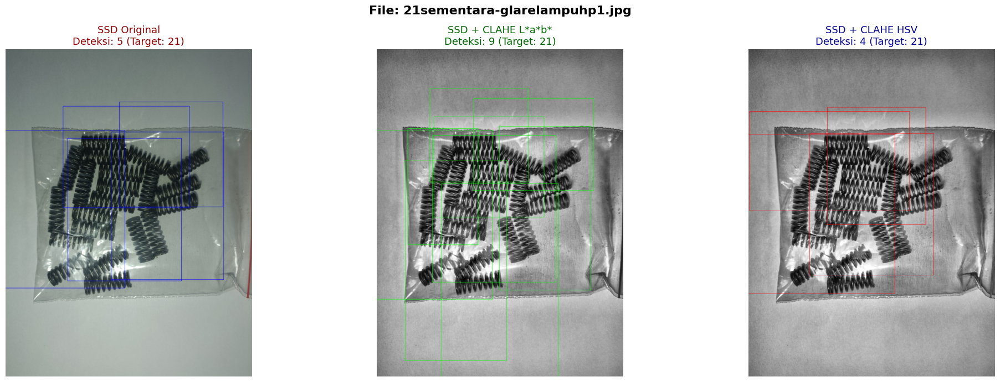

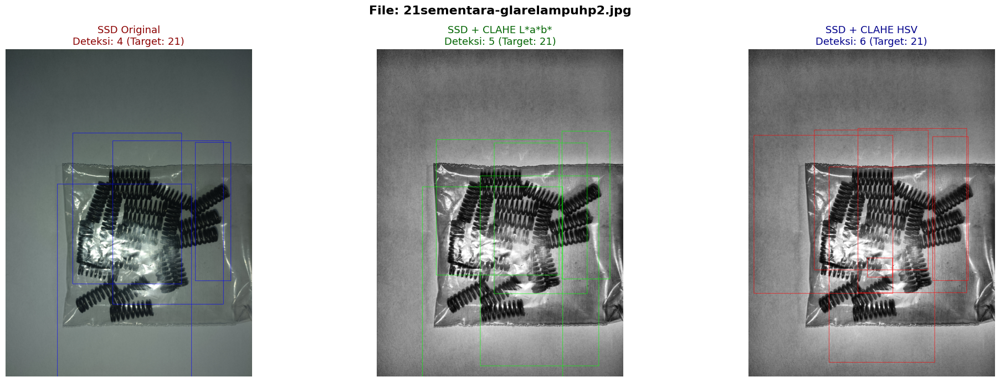

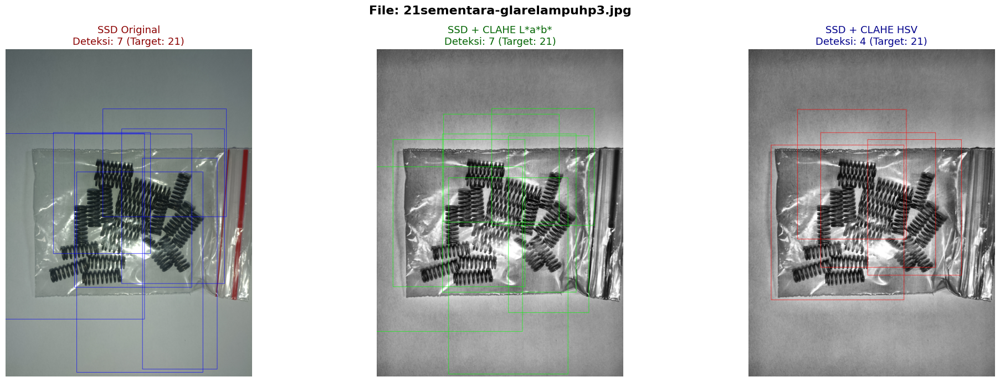

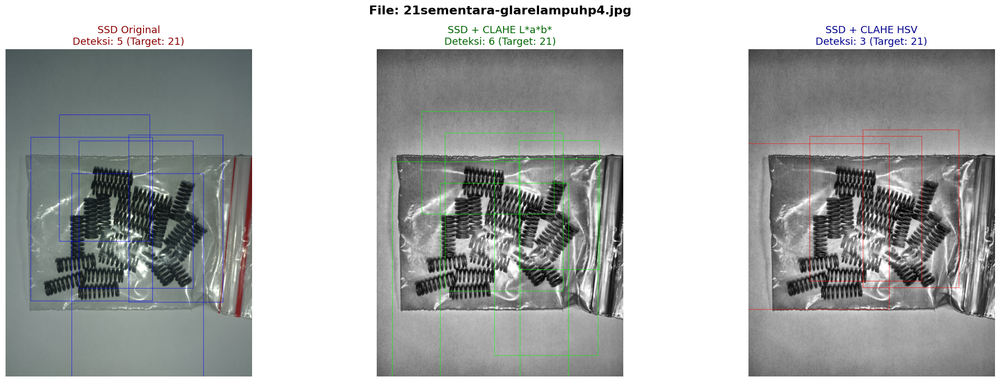

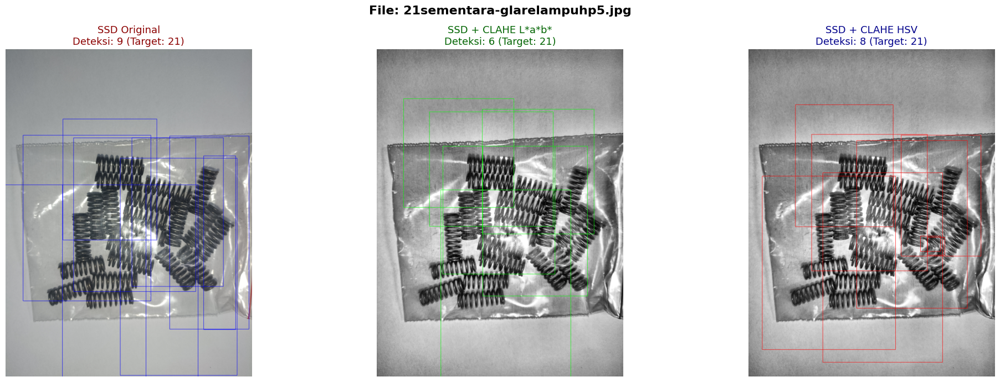

...

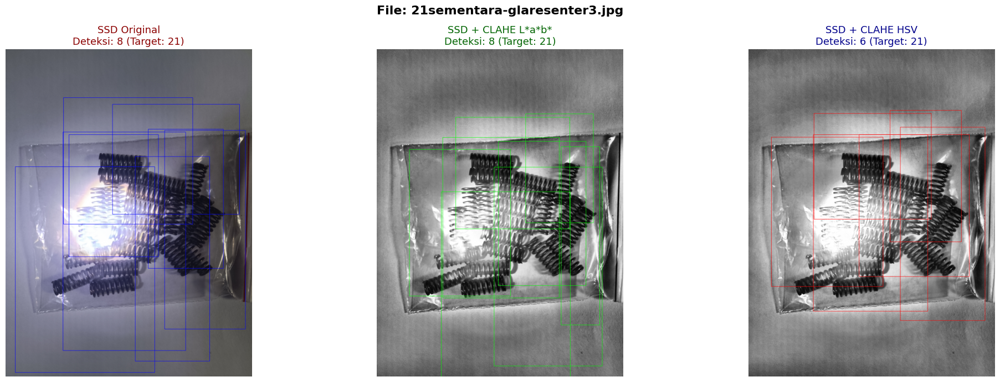

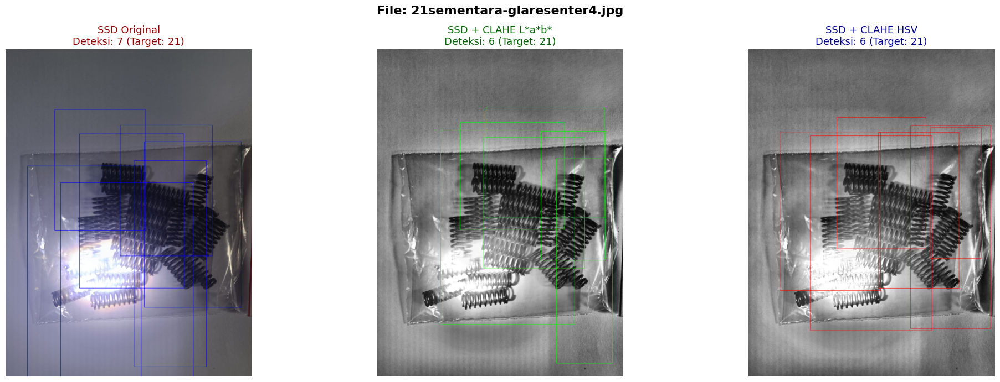

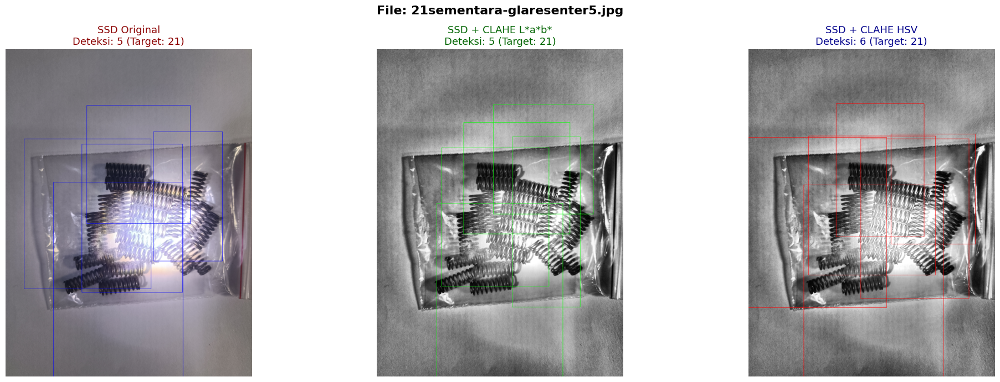

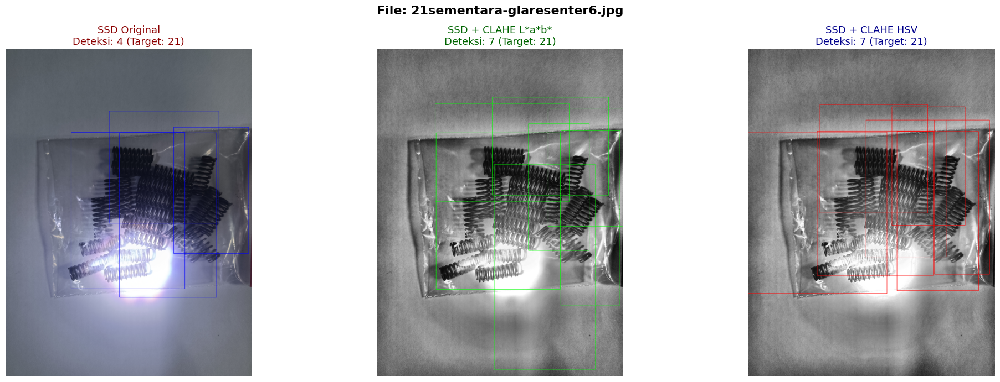

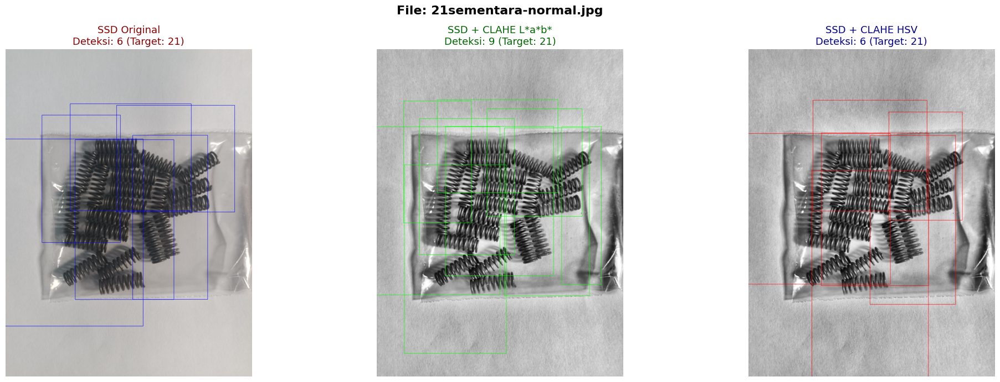


✅ Perbandingan 3 skenario selesai. Hasil di: /content/detect_SSD_CLAHE_comparison


In [ ]:
import os, json
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from ssd_utils import generate_anchors, decode_boxes, to_corners
from ssd_model import build_ssd_mobilenetv2

CONF_THRESH = 0.50
NMS_IOU = 0.45
IMG_SIZE = 320
anchors = generate_anchors()

def load_model(ckpt_dir):
    with open(os.path.join(ckpt_dir, 'classes.json')) as f:
        meta = json.load(f)
    model = build_ssd_mobilenetv2(meta["nc"], pretrained=False)
    model.load_weights(os.path.join(ckpt_dir, "best.weights.h5"))
    return model, meta["names"], meta["nc"]

model_ori, names_ori, nc_ori = load_model("/content/models/S3_Native_SSD_Original")
model_lab, names_lab, nc_lab = load_model("/content/models/S3_Native_SSD_CLAHE_LAB")
model_hsv, names_hsv, nc_hsv = load_model("/content/models/S3_Native_SSD_CLAHE_HSV")

def apply_clahe(img_bgr, mode):
    if mode == 'lab':
        img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(img_lab)
        clahe = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8))
        l_c = clahe.apply(l)
        return cv2.merge((l_c, l_c, l_c))
    elif mode == 'hsv':
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(img_hsv)
        clahe = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8))
        v_c = clahe.apply(v)
        return cv2.merge((v_c, v_c, v_c))
    return img_bgr

def detect(model, num_classes, img_bgr_for_infer):
    h0, w0 = img_bgr_for_infer.shape[:2]
    img_rgb = cv2.cvtColor(img_bgr_for_infer, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE)) / 255.0
    loc_preds, cls_preds = model(np.expand_dims(img_resized.astype(np.float32), 0), training=False)
    probs = tf.nn.softmax(cls_preds, axis=-1).numpy()[0]
    decoded_corners = to_corners(decode_boxes(loc_preds.numpy()[0], anchors))
    boxes, scores = [], []
    for c in range(1, num_classes + 1):
        sc = probs[:, c]
        keep = tf.image.non_max_suppression(
            decoded_corners, sc, max_output_size=100,
            iou_threshold=NMS_IOU, score_threshold=CONF_THRESH).numpy()
        for k in keep:
            boxes.append(decoded_corners[k]); scores.append(sc[k])
    return boxes, w0, h0

def draw_boxes(img_bgr, boxes, w0, h0, color):
    img_out = img_bgr.copy()
    for box in boxes:
        xmin, ymin, xmax, ymax = box
        x1, y1, x2, y2 = int(xmin*w0), int(ymin*h0), int(xmax*w0), int(ymax*h0)
        cv2.rectangle(img_out, (x1, y1), (x2, y2), color, 3)
    return cv2.cvtColor(img_out, cv2.COLOR_BGR2RGB)

test_dir = "/content/test_images_static"
out_dir = "/content/detect_SSD_CLAHE_comparison"
os.makedirs(out_dir, exist_ok=True)

file_list = sorted([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))])
summary = []

for fname in file_list:
    img_bgr = cv2.imread(os.path.join(test_dir, fname))

    boxes_ori, w0, h0 = detect(model_ori, nc_ori, img_bgr)
    img_lab_input = apply_clahe(img_bgr, 'lab')
    boxes_lab, _, _ = detect(model_lab, nc_lab, img_lab_input)
    img_hsv_input = apply_clahe(img_bgr, 'hsv')
    boxes_hsv, _, _ = detect(model_hsv, nc_hsv, img_hsv_input)

    vis_ori = draw_boxes(img_bgr, boxes_ori, w0, h0, (255, 0, 0))
    vis_lab = draw_boxes(img_lab_input, boxes_lab, w0, h0, (0, 255, 0))
    vis_hsv = draw_boxes(img_hsv_input, boxes_hsv, w0, h0, (0, 0, 255))

    plt.figure(figsize=(21, 7))
    plt.subplot(1, 3, 1); plt.imshow(vis_ori); plt.axis('off')
    plt.title(f"SSD Original\nDeteksi: {len(boxes_ori)} (Target: 21)", fontsize=13, color='darkred')
    plt.subplot(1, 3, 2); plt.imshow(vis_lab); plt.axis('off')
    plt.title(f"SSD + CLAHE L*a*b*\nDeteksi: {len(boxes_lab)} (Target: 21)", fontsize=13, color='darkgreen')
    plt.subplot(1, 3, 3); plt.imshow(vis_hsv); plt.axis('off')
    plt.title(f"SSD + CLAHE HSV\nDeteksi: {len(boxes_hsv)} (Target: 21)", fontsize=13, color='darkblue')
    plt.suptitle(f"File: {fname}", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, fname), dpi=120)
    plt.show()

    summary.append({"file": fname, "original": len(boxes_ori), "clahe_lab": len(boxes_lab), "clahe_hsv": len(boxes_hsv)})

with open(os.path.join(out_dir, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(f"\n✅ Perbandingan 3 skenario selesai. Hasil di: {out_dir}")

Original: 100%|██████████| 302/302 [00:09<00:00, 33.05it/s]


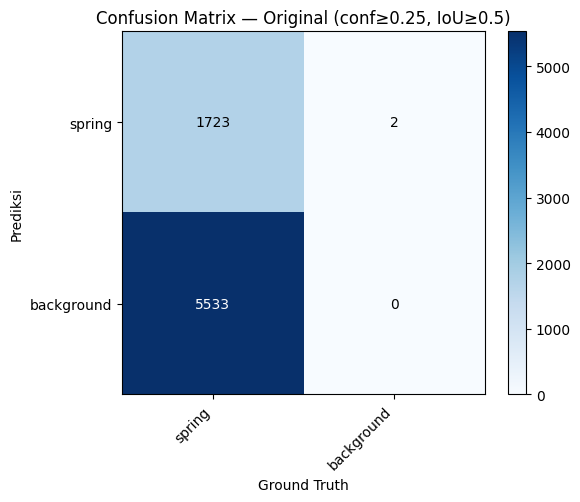

✅ Original: metrics.json & confusion_matrix.png tersimpan di /content/models/S3_Native_SSD_Original



CLAHE-LAB: 100%|██████████| 302/302 [00:05<00:00, 52.66it/s]


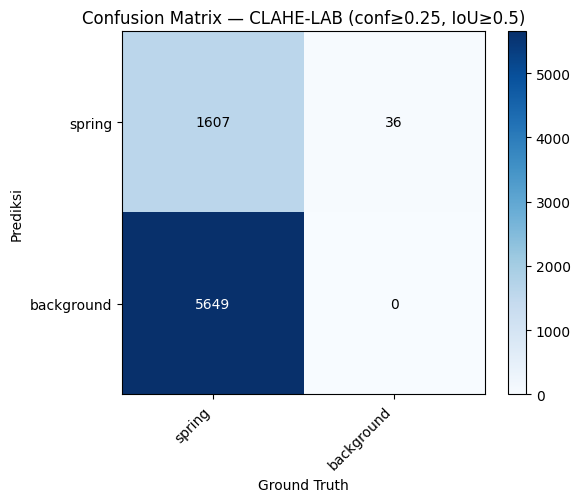

✅ CLAHE-LAB: metrics.json & confusion_matrix.png tersimpan di /content/models/S3_Native_SSD_CLAHE_LAB



CLAHE-HSV: 100%|██████████| 302/302 [00:06<00:00, 46.57it/s]


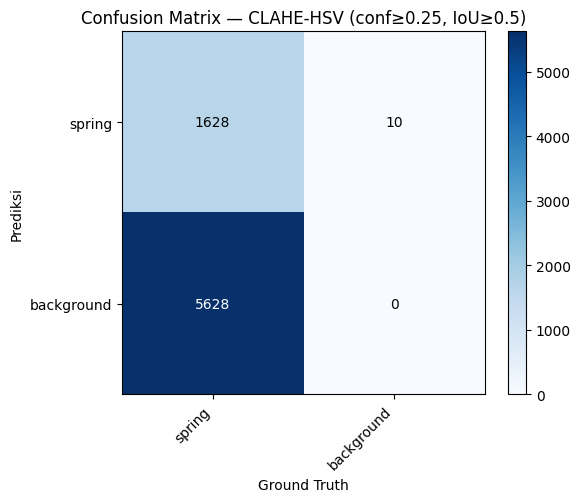

✅ CLAHE-HSV: metrics.json & confusion_matrix.png tersimpan di /content/models/S3_Native_SSD_CLAHE_HSV



In [ ]:
import os, json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tqdm import tqdm
from ssd_utils import generate_anchors, decode_boxes, to_corners, evaluate_class_ap, iou_matrix
from ssd_model import build_ssd_mobilenetv2
from data_pipeline import list_image_label_pairs, parse_yolo_label, load_image, IMG_SIZE

anchors = generate_anchors()

def full_evaluate_and_save(ckpt_dir, dataset_dir, label):
    with open(os.path.join(ckpt_dir, 'classes.json')) as f:
        meta = json.load(f)
    class_names, num_classes = meta["names"], meta["nc"]

    valid_img_dir = os.path.join(dataset_dir, "valid", "images")
    valid_lbl_dir = os.path.join(dataset_dir, "valid", "labels")
    if not (os.path.isdir(valid_img_dir) and len(os.listdir(valid_img_dir)) > 0):
        valid_img_dir = os.path.join(dataset_dir, "train", "images")
        valid_lbl_dir = os.path.join(dataset_dir, "train", "labels")

    model = build_ssd_mobilenetv2(num_classes, pretrained=False)
    model.load_weights(os.path.join(ckpt_dir, "best.weights.h5"))

    @tf.function
    def infer(img_batch):
        return model(img_batch, training=False)

    pairs = list_image_label_pairs(valid_img_dir, valid_lbl_dir)
    all_preds = {c: [] for c in range(num_classes)}
    all_gts = {c: [] for c in range(num_classes)}
    n_instances_per_class = {c: 0 for c in range(num_classes)}

    for img_id, (img_path, lbl_path) in enumerate(tqdm(pairs, desc=label)):
        img = load_image(img_path, IMG_SIZE)
        if img is None:
            continue
        gt_boxes, gt_classes = parse_yolo_label(lbl_path)
        gt_corners = to_corners(gt_boxes) if gt_boxes.shape[0] > 0 else np.zeros((0, 4))
        for box, cls in zip(gt_corners, gt_classes):
            all_gts[int(cls)].append((img_id, box))
            n_instances_per_class[int(cls)] += 1

        loc_preds, cls_preds = infer(np.expand_dims(img, 0).astype(np.float32))
        probs = tf.nn.softmax(cls_preds, axis=-1).numpy()[0]
        decoded_corners = to_corners(decode_boxes(loc_preds.numpy()[0], anchors))
        for c in range(1, num_classes + 1):
            scores = probs[:, c]
            keep = tf.image.non_max_suppression(
                decoded_corners, scores, max_output_size=50,
                iou_threshold=0.45, score_threshold=0.01).numpy()
            for k in keep:
                all_preds[c - 1].append((img_id, float(scores[k]), decoded_corners[k]))

    # mAP50 & mAP50-95
    iou_thresholds = np.arange(0.5, 1.0, 0.05)
    per_class_ap50, per_class_ap5095, per_class_p, per_class_r = {}, {}, {}, {}
    for c in range(num_classes):
        ap50, r50, p50 = evaluate_class_ap(all_preds[c], all_gts[c], iou_thresh=0.5)
        aps_all_iou = [evaluate_class_ap(all_preds[c], all_gts[c], iou_thresh=t)[0] for t in iou_thresholds]
        per_class_ap50[c] = ap50; per_class_ap5095[c] = float(np.mean(aps_all_iou))
        per_class_p[c] = p50; per_class_r[c] = r50

    metrics = {
        "images": len(pairs), "instances": sum(n_instances_per_class.values()),
        "precision": float(np.mean(list(per_class_p.values()))),
        "recall": float(np.mean(list(per_class_r.values()))),
        "mAP50": float(np.mean(list(per_class_ap50.values()))),
        "mAP50_95": float(np.mean(list(per_class_ap5095.values()))),
        "per_class": {class_names[c]: {"P": per_class_p[c], "R": per_class_r[c],
                      "mAP50": per_class_ap50[c], "mAP50_95": per_class_ap5095[c]} for c in range(num_classes)}
    }
    with open(os.path.join(ckpt_dir, "metrics.json"), "w") as f:
        json.dump(metrics, f, indent=2)

    # Confusion matrix
    CONF_THRESH_CM = 0.25
    confusion = np.zeros((num_classes + 1, num_classes + 1), dtype=int)
    for img_id, (img_path, lbl_path) in enumerate(pairs):
        gt_boxes, gt_classes = parse_yolo_label(lbl_path)
        gt_corners = to_corners(gt_boxes) if gt_boxes.shape[0] > 0 else np.zeros((0, 4))
        dets = []
        for c in range(num_classes):
            for pid, score, box in all_preds[c]:
                if pid == img_id and score >= CONF_THRESH_CM:
                    dets.append((box, score, c))
        matched_gt = np.zeros(len(gt_corners), dtype=bool)
        for db, ds_, dc in sorted(dets, key=lambda x: -x[1]):
            if len(gt_corners) > 0:
                ious = iou_matrix(np.array([db]), gt_corners)[0]
                j = np.argmax(ious)
                if ious[j] >= 0.5 and not matched_gt[j]:
                    confusion[dc, int(gt_classes[j])] += 1
                    matched_gt[j] = True
                    continue
            confusion[dc, num_classes] += 1
        for j, matched in enumerate(matched_gt):
            if not matched:
                confusion[num_classes, int(gt_classes[j])] += 1

    labels = class_names + ["background"]
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(confusion, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Ground Truth"); ax.set_ylabel("Prediksi")
    ax.set_title(f"Confusion Matrix — {label} (conf≥{CONF_THRESH_CM}, IoU≥0.5)")
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, confusion[i, j], ha="center", va="center",
                     color="white" if confusion[i, j] > confusion.max()/2 else "black")
    plt.colorbar(im); plt.tight_layout()
    plt.savefig(os.path.join(ckpt_dir, "confusion_matrix.png"), dpi=150)
    plt.show()
    print(f"✅ {label}: metrics.json & confusion_matrix.png tersimpan di {ckpt_dir}\n")

with open('dataset_path.txt') as f: dataset_ori = f.read().strip()
with open('dataset_path_lab.txt') as f: dataset_lab = f.read().strip()
with open('dataset_path_hsv.txt') as f: dataset_hsv = f.read().strip()

full_evaluate_and_save("/content/models/S3_Native_SSD_Original", dataset_ori, "Original")
full_evaluate_and_save("/content/models/S3_Native_SSD_CLAHE_LAB", dataset_lab, "CLAHE-LAB")
full_evaluate_and_save("/content/models/S3_Native_SSD_CLAHE_HSV", dataset_hsv, "CLAHE-HSV")